# MarketPulse — Week 3: Market Exploratory Data Analysis (EDA)
**Author:** Mariam  
**Milestone:** Week 3 (Oct 12 → Oct 18)  
**Input:** `data/processed/market_clean.csv`  
**Output:** this notebook, with charts

## Week 3 tasks
**Produce price analysis:**
1. Price trends
2. Cumulative returns
3. Daily returns
4. Trading volume
5. Moving averages

**Answer the questions:**
- How did prices change?
- Which companies experienced large movements?
- When were major changes observed?
- How does trading volume behave?

## 1. Setup and data loading
The notebook finds the repository root by walking up from the current folder until it finds `data/processed/market_clean.csv`, so it runs on any computer.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (13, 6)
plt.rcParams["font.size"] = 11

def find_repo_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "data" / "processed" / "market_clean.csv").exists():
            return folder
    raise FileNotFoundError("Could not find data/processed/market_clean.csv")

REPO_ROOT = find_repo_root(Path.cwd().resolve())
df = pd.read_csv(REPO_ROOT / "data" / "processed" / "market_clean.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)
df["year"] = df["date"].dt.year
tickers = sorted(df["ticker"].unique())

print(f"Rows x columns: {df.shape[0]:,} x {df.shape[1]}")
print(f"Date range:     {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Tickers ({len(tickers)}):   {', '.join(tickers)}")
df.head()

Rows x columns: 12,540 x 10
Date range:     2021-01-04 to 2025-12-30
Tickers (10):   AAPL, AMZN, JNJ, JPM, KO, LLY, MSFT, NVDA, TSLA, XOM


,ticker,date,open,high,low,close,volume,return,next_day_return,year
0,AAPL,2021-01-04,129.6225,129.7099,123.0599,125.6325,143301900,NaN,0.012363,2021
1,AAPL,2021-01-05,125.1276,127.8945,124.6811,127.1858,97664900,0.012363,-0.033661,2021
2,AAPL,2021-01-06,123.9918,127.2246,122.6909,122.9045,155088000,-0.033661,0.034124,2021
3,AAPL,2021-01-07,124.6132,127.7877,124.1278,127.0985,109578200,0.034124,0.008631,2021
4,AAPL,2021-01-08,128.5643,128.7585,126.4286,128.1954,105158200,0.008631,-0.023249,2021


## 2. Price trends
Share prices are on very different scales (for example `KO` stays between about \$40 and \$71 while `LLY` goes above \$1,100), so we show:
1. A summary table of start, end, lowest and highest closing price per company.
2. Each company's closing price in its own panel.
3. A normalized price index (every stock starts at 100 on the first day) so all 10 companies can be compared on one chart:

$$\text{Normalized Price}_t = 100 \times \frac{\text{Close}_t}{\text{Close}_0}$$

In [2]:
first = df.groupby("ticker").first()
last = df.groupby("ticker").last()
low_idx = df.groupby("ticker")["close"].idxmin()
high_idx = df.groupby("ticker")["close"].idxmax()

price_summary = pd.DataFrame({
    "start_close": first["close"],
    "end_close": last["close"],
    "change_pct": (last["close"] / first["close"] - 1) * 100,
    "lowest_close": df.loc[low_idx].set_index("ticker")["close"],
    "lowest_date": df.loc[low_idx].set_index("ticker")["date"].dt.strftime("%Y-%m-%d"),
    "highest_close": df.loc[high_idx].set_index("ticker")["close"],
    "highest_date": df.loc[high_idx].set_index("ticker")["date"].dt.strftime("%Y-%m-%d"),
}).sort_values("change_pct", ascending=False)
price_summary.round(2)

,start_close,end_close,change_pct,lowest_close,lowest_date,highest_close,highest_date
ticker,,,,,,,
NVDA,13.05,187.10,1334.15,11.19,2022-10-14,206.55,2025-10-29
LLY,156.30,1074.56,587.49,155.19,2021-01-06,1104.60,2025-11-25
XOM,33.25,118.61,256.71,33.25,2021-01-04,118.61,2025-12-30
JPM,108.46,317.31,192.56,92.91,2022-10-11,322.95,2025-12-24
MSFT,207.57,484.41,133.38,202.38,2021-01-06,537.65,2025-10-28
AAPL,125.63,272.34,116.77,113.13,2021-03-08,285.41,2025-12-02
TSLA,243.26,454.43,86.81,108.10,2023-01-03,489.88,2025-12-16
KO,44.53,68.73,54.37,40.64,2021-01-29,71.23,2025-11-28
JNJ,133.63,203.63,52.39,131.51,2021-03-04,210.78,2025-12-15


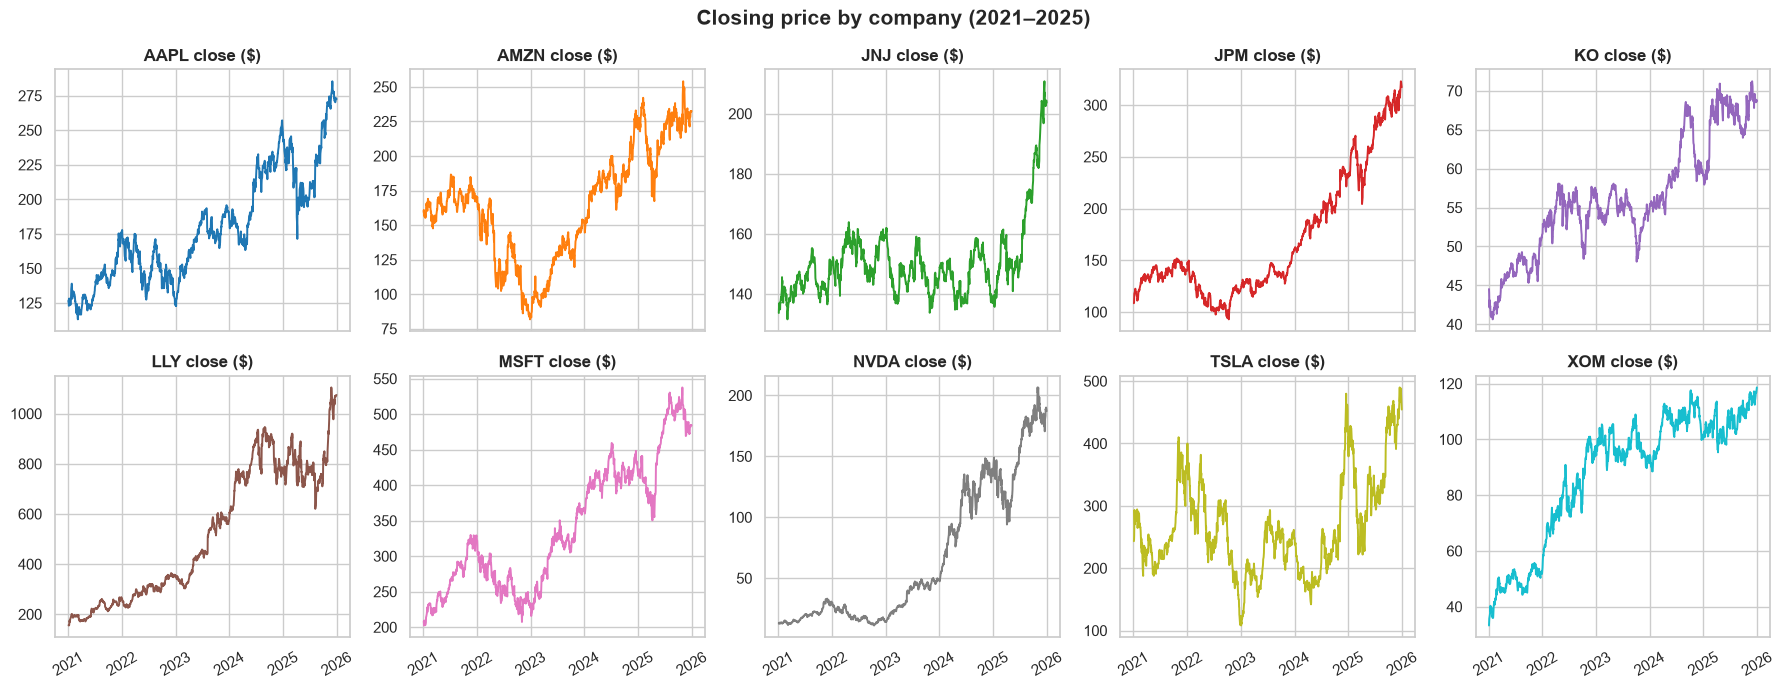

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharex=True)
palette = sns.color_palette("tab10", len(tickers))
for ax, ticker, color in zip(axes.flatten(), tickers, palette):
    sub = df[df["ticker"] == ticker]
    ax.plot(sub["date"], sub["close"], color=color, linewidth=1.4)
    ax.set_title(f"{ticker} close ($)", fontweight="bold")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Closing price by company (2021–2025)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

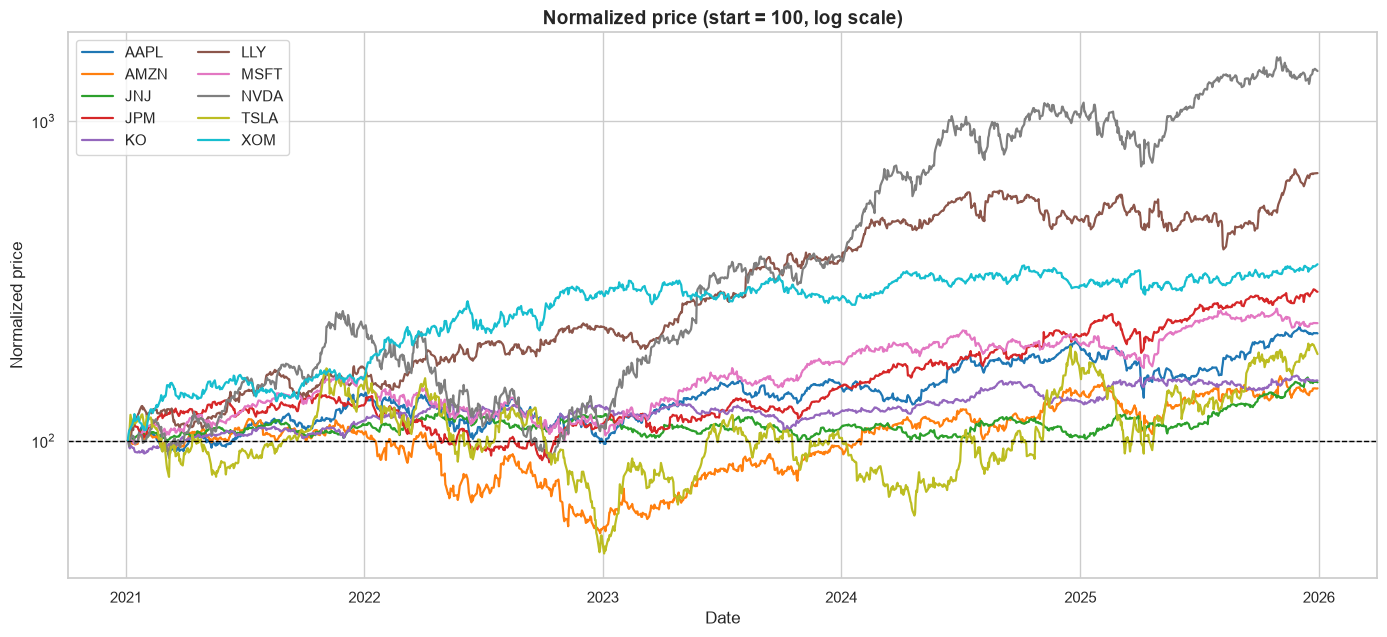

In [4]:
df["normalized_price"] = df.groupby("ticker")["close"].transform(lambda s: s / s.iloc[0] * 100)

plt.figure(figsize=(14, 6.5))
for ticker in tickers:
    sub = df[df["ticker"] == ticker]
    plt.plot(sub["date"], sub["normalized_price"], label=ticker, linewidth=1.6)
plt.axhline(100, color="black", linestyle="--", linewidth=1)
plt.yscale("log")
plt.title("Normalized price (start = 100, log scale)", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Normalized price")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 3. Cumulative returns
Cumulative return is the total gain or loss from the first trading day up to day $t$:

$$\text{Cumulative Return}_t = \frac{\text{Close}_t}{\text{Close}_0} - 1$$

Below we also break the five years down into calendar-year returns, to see *when* the gains and losses happened.

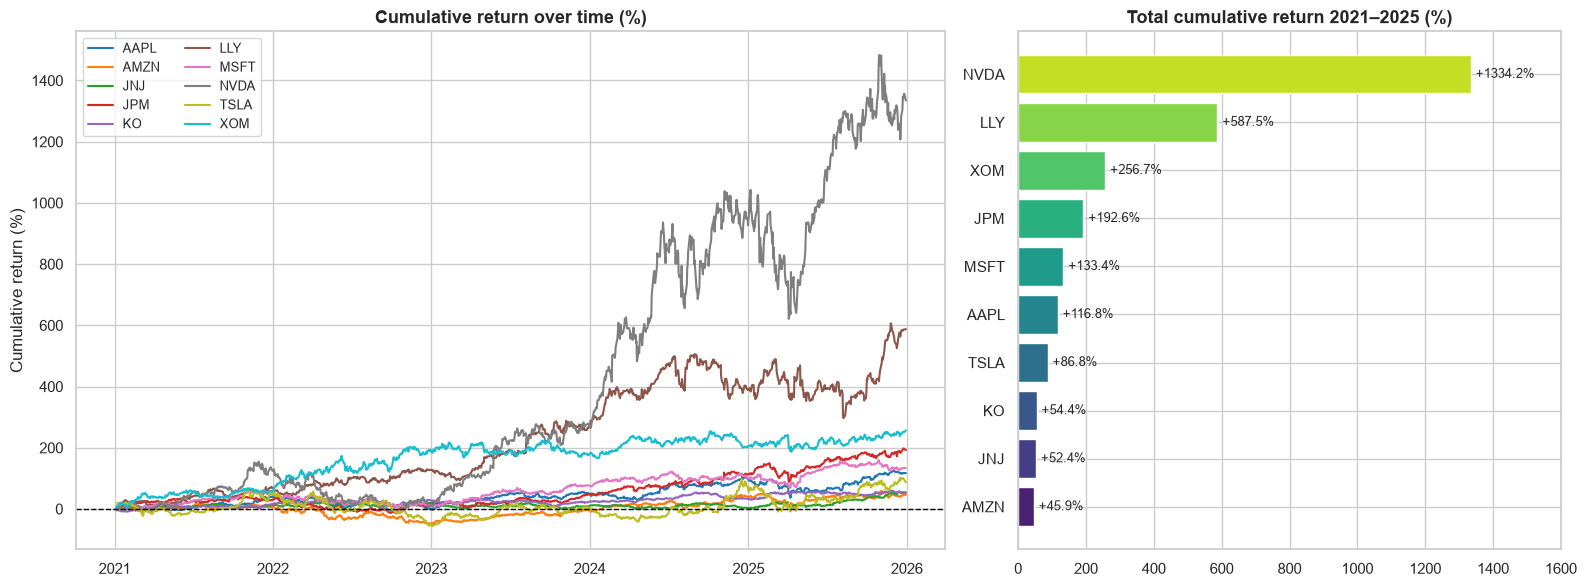

In [5]:
df["cumulative_return"] = df.groupby("ticker")["close"].transform(lambda s: s / s.iloc[0] - 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.6, 1]})
for ticker in tickers:
    sub = df[df["ticker"] == ticker]
    ax1.plot(sub["date"], sub["cumulative_return"] * 100, label=ticker, linewidth=1.5)
ax1.axhline(0, color="black", linestyle="--", linewidth=1)
ax1.set_title("Cumulative return over time (%)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Cumulative return (%)")
ax1.legend(ncol=2, fontsize=9)

final_cum = df.groupby("ticker")["cumulative_return"].last().mul(100).sort_values()
bars = ax2.barh(final_cum.index, final_cum.values, color=sns.color_palette("viridis", len(final_cum)))
for bar in bars:
    ax2.text(bar.get_width() + 15, bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():+.1f}%", va="center", fontsize=9.5)
ax2.set_xlim(0, final_cum.max() * 1.2)
ax2.set_title("Total cumulative return 2021–2025 (%)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [6]:
# Calendar-year return: last close of the year vs last close of the previous year
# (for 2021: vs the first close in the dataset)
year_end_close = df.groupby(["ticker", "year"])["close"].last().unstack()
previous_close = year_end_close.shift(1, axis=1)
previous_close[year_end_close.columns[0]] = df.groupby("ticker")["close"].first()
yearly_return_pct = (year_end_close / previous_close - 1) * 100
yearly_return_pct.round(1)

year,2021,2022,2023,2024,2025
ticker,,,,,
AAPL,38.1,-26.4,49.0,30.7,9.5
AMZN,4.6,-49.6,80.9,44.4,6.0
JNJ,12.1,6.0,-8.6,-4.8,47.5
JPM,29.0,-12.6,30.6,44.3,37.8
KO,15.8,10.6,-4.4,8.9,15.9
LLY,69.4,34.3,60.9,33.3,40.9
MSFT,55.8,-28.0,58.2,12.9,16.5
NVDA,124.5,-50.3,239.0,171.2,39.7
TSLA,44.8,-65.0,101.7,62.5,12.5


## 4. Daily returns
Daily return is the percentage change in closing price from the previous trading day:

$$R_t = \frac{\text{Close}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$$

We summarize daily returns per company, count large-move days (absolute daily return above 5%) per year, and plot the distribution.

In [7]:
best_idx = df.groupby("ticker")["return"].idxmax()
worst_idx = df.groupby("ticker")["return"].idxmin()
df["large_move"] = df["return"].abs() > 0.05

daily_stats = pd.DataFrame({
    "mean_pct": df.groupby("ticker")["return"].mean() * 100,
    "std_pct": df.groupby("ticker")["return"].std() * 100,
    "best_day_pct": df.loc[best_idx].set_index("ticker")["return"] * 100,
    "best_day": df.loc[best_idx].set_index("ticker")["date"].dt.strftime("%Y-%m-%d"),
    "worst_day_pct": df.loc[worst_idx].set_index("ticker")["return"] * 100,
    "worst_day": df.loc[worst_idx].set_index("ticker")["date"].dt.strftime("%Y-%m-%d"),
    "days_abs_move_over_5pct": df.groupby("ticker")["large_move"].sum(),
}).sort_values("std_pct", ascending=False)
daily_stats.round(2)

,mean_pct,std_pct,best_day_pct,best_day,worst_day_pct,worst_day,days_abs_move_over_5pct
ticker,,,,,,,
TSLA,0.12,3.83,22.69,2025-04-09,-15.43,2025-03-10,195
NVDA,0.27,3.29,24.37,2023-05-25,-16.97,2025-01-27,134
AMZN,0.05,2.21,13.54,2022-02-04,-14.05,2022-04-29,39
LLY,0.17,2.01,14.87,2023-08-08,-14.14,2025-08-07,25
AAPL,0.08,1.76,15.33,2025-04-09,-9.25,2025-04-03,15
XOM,0.12,1.70,6.41,2022-02-01,-7.89,2022-05-09,12
MSFT,0.08,1.62,10.13,2025-04-09,-7.72,2022-10-26,12
JPM,0.10,1.53,11.54,2024-11-06,-7.48,2025-04-04,12
JNJ,0.04,1.05,6.19,2025-07-16,-7.59,2025-04-01,3


In [8]:
large_moves_by_year = df.pivot_table(index="ticker", columns="year", values="large_move", aggfunc="sum")
large_moves_by_year.loc["ALL"] = large_moves_by_year.sum()
large_moves_by_year

year,2021,2022,2023,2024,2025
ticker,,,,,
AAPL,1,7,0,2,5
AMZN,1,23,6,3,6
JNJ,0,0,1,0,2
JPM,0,4,2,3,3
KO,0,1,0,0,0
LLY,6,1,2,6,10
MSFT,0,7,1,1,3
NVDA,19,58,14,24,19
TSLA,27,58,34,36,40


In [9]:
# Equal-weight average daily return of the 10 stocks: the 5 strongest and 5 weakest days
avg_daily_return = df.pivot(index="date", columns="ticker", values="return").mean(axis=1) * 100
extreme_days = pd.concat([avg_daily_return.nlargest(5), avg_daily_return.nsmallest(5)]).rename("avg_return_pct")
extreme_days.index = extreme_days.index.strftime("%Y-%m-%d")
extreme_days.round(2).to_frame()

,avg_return_pct
date,
2025-04-09,9.86
2022-11-10,6.29
2022-11-30,3.89
2022-06-21,3.69
2025-05-12,3.49
2025-04-04,-6.25
2022-09-13,-4.64
2022-05-18,-4.51
2025-04-03,-4.42


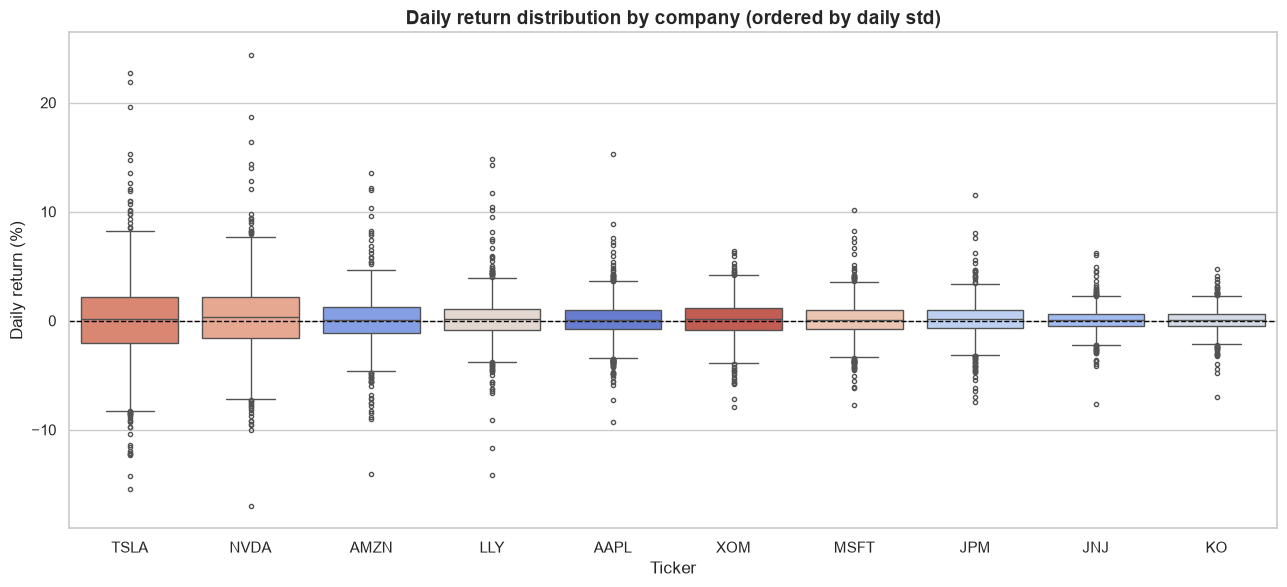

In [10]:
plt.figure(figsize=(13, 6))
sns.boxplot(
    data=df.dropna(subset=["return"]).assign(return_pct=lambda d: d["return"] * 100),
    x="ticker", y="return_pct", hue="ticker", order=daily_stats.index.tolist(),
    palette="coolwarm", legend=False, fliersize=3,
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Daily return distribution by company (ordered by daily std)", fontsize=14, fontweight="bold")
plt.xlabel("Ticker")
plt.ylabel("Daily return (%)")
plt.tight_layout()
plt.show()

## 5. Trading volume
Volume is the number of shares traded per day. We look at:
1. Average and peak volume per company.
2. Average daily volume per year.
3. How each day's volume compares with its own 20-day average (`volume / 20-day average volume`), and whether volume is higher on large-move days.

In [11]:
peak_idx = df.groupby("ticker")["volume"].idxmax()
volume_summary = pd.DataFrame({
    "avg_volume_M": df.groupby("ticker")["volume"].mean() / 1e6,
    "median_volume_M": df.groupby("ticker")["volume"].median() / 1e6,
    "peak_volume_M": df.loc[peak_idx].set_index("ticker")["volume"] / 1e6,
    "peak_volume_date": df.loc[peak_idx].set_index("ticker")["date"].dt.strftime("%Y-%m-%d"),
    "return_on_peak_day_pct": df.loc[peak_idx].set_index("ticker")["return"] * 100,
}).sort_values("avg_volume_M", ascending=False)
volume_summary.round(2)

,avg_volume_M,median_volume_M,peak_volume_M,peak_volume_date,return_on_peak_day_pct
ticker,,,,,
NVDA,395.10,380.55,1543.91,2023-05-25,24.37
TSLA,99.79,93.12,306.59,2023-01-27,11.00
AAPL,69.85,63.14,318.68,2024-09-20,-0.29
AMZN,57.65,51.53,272.66,2022-04-29,-14.05
MSFT,25.54,23.19,90.43,2022-01-26,2.85
XOM,19.84,17.66,84.44,2021-03-19,-0.56
KO,15.26,13.90,67.85,2021-03-19,0.47
JPM,11.15,9.67,54.42,2021-03-19,-1.59
JNJ,8.32,7.02,151.32,2023-08-21,-2.98


In [12]:
avg_volume_by_year_M = df.pivot_table(index="ticker", columns="year", values="volume", aggfunc="mean") / 1e6
avg_volume_by_year_M.round(1)

year,2021,2022,2023,2024,2025
ticker,,,,,
AAPL,90.5,87.9,59.2,57.1,54.3
AMZN,67.8,76.1,58.8,41.0,44.5
JNJ,7.1,7.3,11.2,7.2,8.9
JPM,12.9,13.7,10.7,9.0,9.4
KO,15.8,16.0,13.8,14.0,16.7
LLY,3.4,2.9,3.1,3.2,4.0
MSFT,26.0,31.2,27.7,20.6,22.2
NVDA,359.6,543.2,473.6,377.2,221.2
TSLA,82.2,86.9,137.4,94.8,97.9


In [13]:
df["volume_ma20"] = df.groupby("ticker")["volume"].transform(lambda s: s.rolling(20).mean())
df["volume_ratio"] = df["volume"] / df["volume_ma20"]
vr = df.dropna(subset=["volume_ratio", "return"])

volume_ratio_stats = pd.DataFrame({
    "median_ratio": vr.groupby("ticker")["volume_ratio"].median(),
    "pct_days_over_1_5x": vr.groupby("ticker")["volume_ratio"].apply(lambda s: (s > 1.5).mean() * 100),
    "pct_days_over_2x": vr.groupby("ticker")["volume_ratio"].apply(lambda s: (s > 2).mean() * 100),
    "max_ratio": vr.groupby("ticker")["volume_ratio"].max(),
    "corr_abs_return_vs_ratio": vr.groupby("ticker").apply(lambda g: g["return"].abs().corr(g["volume_ratio"])),
})
print(f"All tickers: {(vr['volume_ratio'] > 1.5).mean() * 100:.2f}% of days above 1.5x, "
      f"{(vr['volume_ratio'] > 2).mean() * 100:.2f}% above 2x the 20-day average")
print(f"Median volume ratio on large-move days (|return| > 5%): {vr.loc[vr['large_move'], 'volume_ratio'].median():.2f}")
print(f"Median volume ratio on other days:                      {vr.loc[~vr['large_move'], 'volume_ratio'].median():.2f}")
volume_ratio_stats.round(2)

All tickers: 7.48% of days above 1.5x, 2.19% above 2x the 20-day average
Median volume ratio on large-move days (|return| > 5%): 1.27
Median volume ratio on other days:                      0.92


,median_ratio,pct_days_over_1_5x,pct_days_over_2x,max_ratio,corr_abs_return_vs_ratio
ticker,,,,,
AAPL,0.92,7.21,1.78,5.25,0.42
AMZN,0.92,7.94,3.08,3.72,0.54
JNJ,0.95,7.94,2.35,3.60,0.39
JPM,0.93,7.45,3.32,3.57,0.50
KO,0.93,6.48,1.54,4.31,0.31
LLY,0.89,10.53,3.64,6.30,0.63
MSFT,0.92,7.61,2.35,2.97,0.46
NVDA,0.94,7.21,1.54,4.19,0.50
TSLA,0.96,6.07,1.05,2.89,0.53


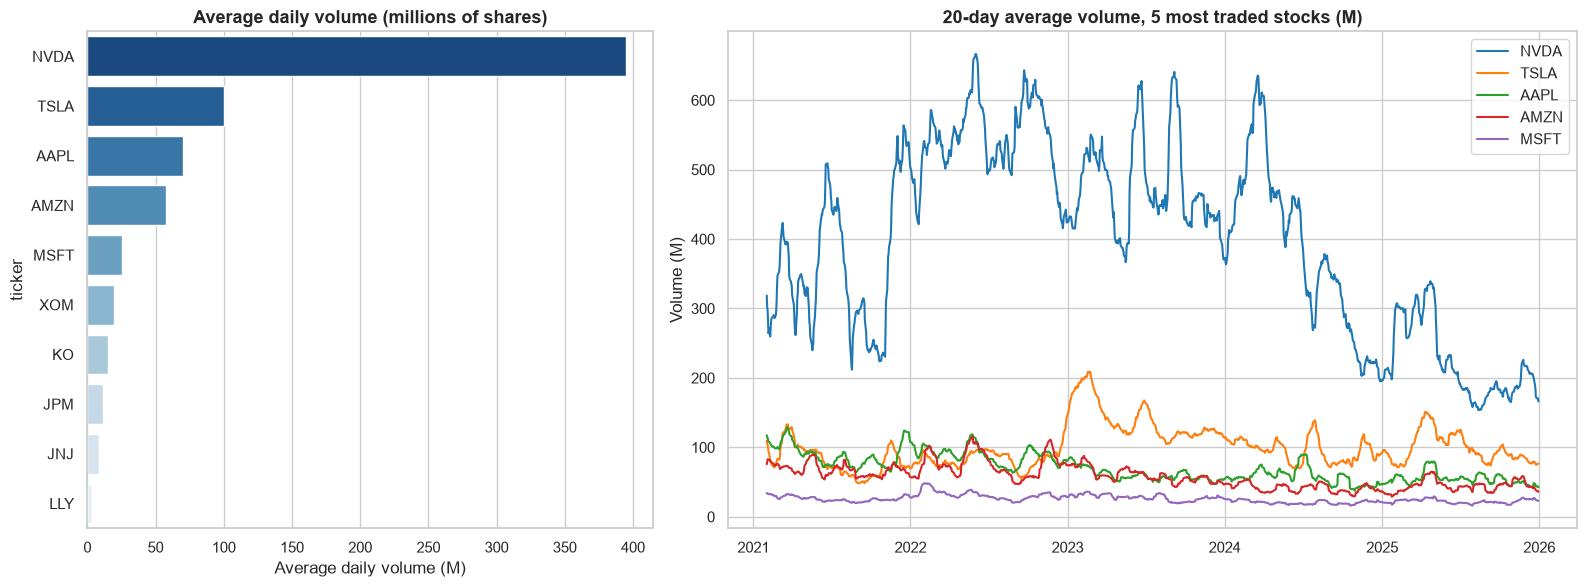

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.5]})
sns.barplot(data=volume_summary.reset_index(), x="avg_volume_M", y="ticker",
            hue="ticker", palette="Blues_r", legend=False, ax=ax1)
ax1.set_title("Average daily volume (millions of shares)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Average daily volume (M)")

for ticker in volume_summary.index[:5]:
    sub = df[df["ticker"] == ticker]
    ax2.plot(sub["date"], sub["volume_ma20"] / 1e6, label=ticker, linewidth=1.5)
ax2.set_title("20-day average volume, 5 most traded stocks (M)", fontsize=13, fontweight="bold")
ax2.set_ylabel("Volume (M)")
ax2.legend()
plt.tight_layout()
plt.show()

## 6. Moving averages (MA20, MA50, MA200)
A moving average is the mean closing price over the last N trading days. It smooths daily noise so the trend is easier to see:
- **MA20**: short-term trend (about 1 trading month)
- **MA50**: medium-term trend (about 1 quarter)
- **MA200**: long-term trend (about 1 trading year)

When the price stays above its MA200, the stock is in a long-term uptrend; below it, a long-term downtrend. The table after the chart shows the share of days each stock closed above its MA200 in each year.

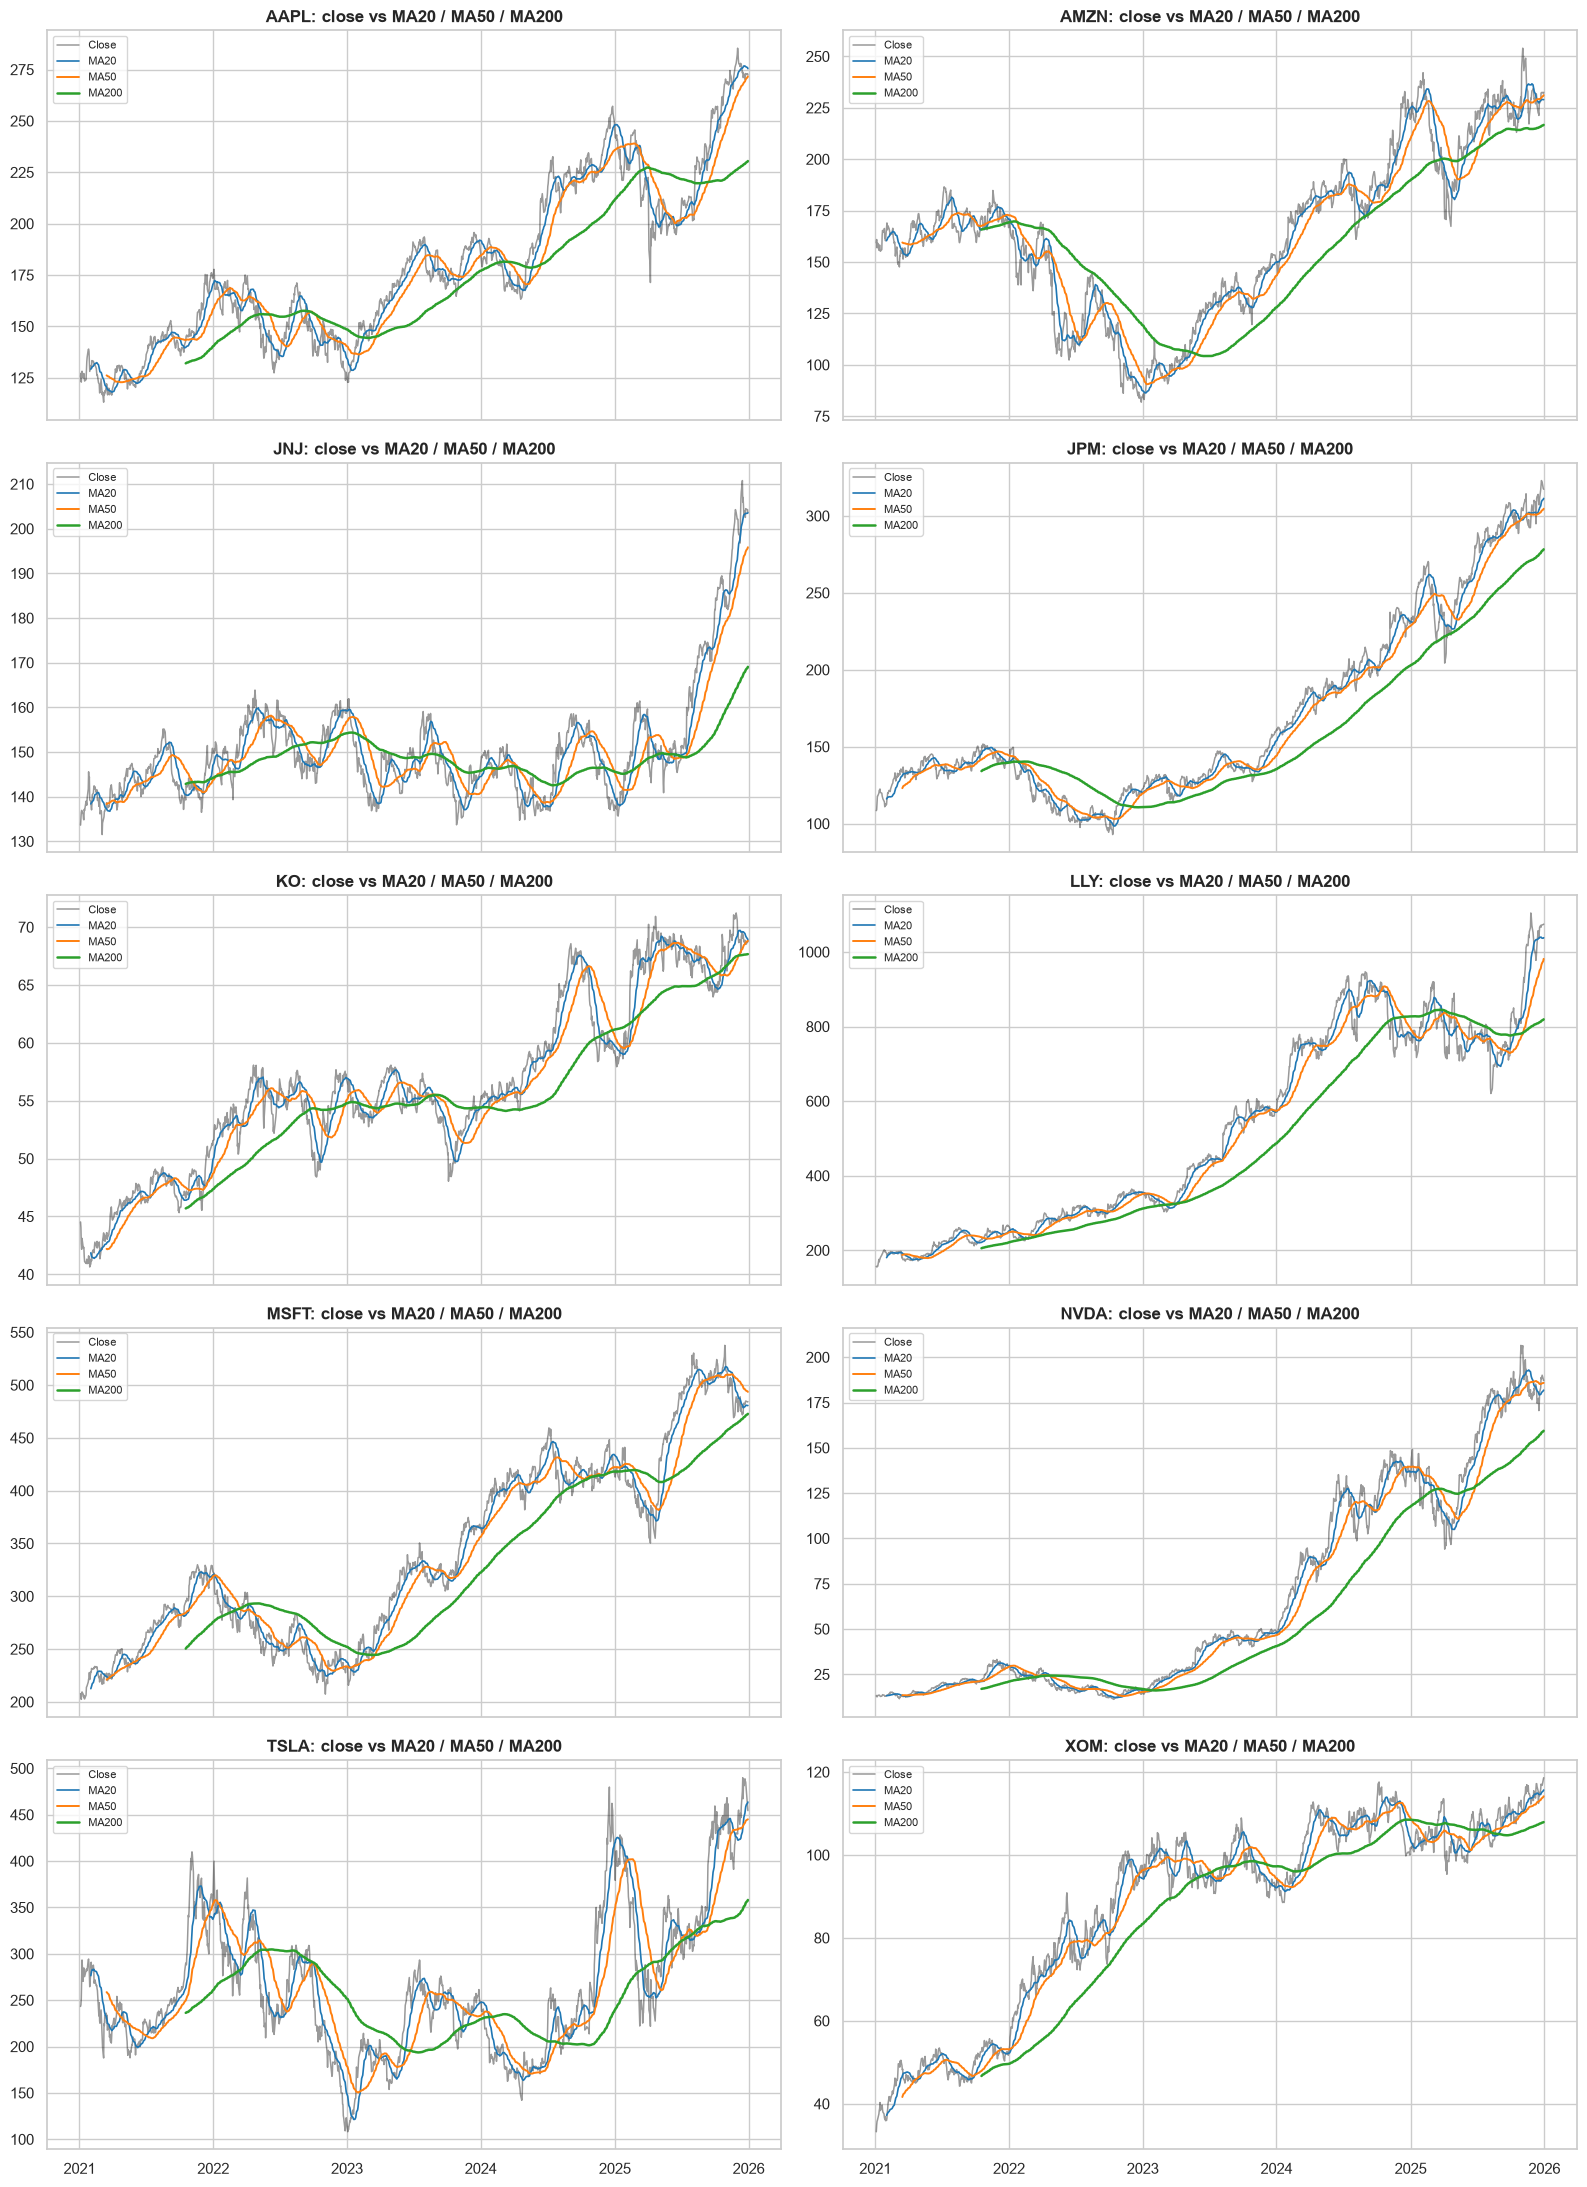

In [15]:
for n in (20, 50, 200):
    df[f"ma{n}"] = df.groupby("ticker")["close"].transform(lambda s: s.rolling(n).mean())

fig, axes = plt.subplots(5, 2, figsize=(16, 22), sharex=True)
for ax, ticker in zip(axes.flatten(), tickers):
    sub = df[df["ticker"] == ticker]
    ax.plot(sub["date"], sub["close"], label="Close", color="black", alpha=0.4, linewidth=1.1)
    ax.plot(sub["date"], sub["ma20"], label="MA20", linewidth=1.2)
    ax.plot(sub["date"], sub["ma50"], label="MA50", linewidth=1.4)
    ax.plot(sub["date"], sub["ma200"], label="MA200", linewidth=1.8)
    ax.set_title(f"{ticker}: close vs MA20 / MA50 / MA200", fontweight="bold")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
has_ma200 = df.dropna(subset=["ma200"]).copy()
has_ma200["above_ma200"] = has_ma200["close"] > has_ma200["ma200"]
pct_days_above_ma200 = has_ma200.pivot_table(index="ticker", columns="year", values="above_ma200", aggfunc="mean") * 100
pct_days_above_ma200.round(0)

year,2021,2022,2023,2024,2025
ticker,,,,,
AAPL,100.0,41.0,89.0,79.0,58.0
AMZN,89.0,2.0,66.0,96.0,84.0
JNJ,40.0,74.0,25.0,54.0,77.0
JPM,91.0,22.0,98.0,100.0,97.0
KO,91.0,81.0,42.0,86.0,78.0
LLY,100.0,97.0,91.0,85.0,37.0
MSFT,100.0,17.0,89.0,89.0,72.0
NVDA,100.0,24.0,97.0,100.0,78.0
TSLA,100.0,33.0,55.0,51.0,73.0


## 7. Answers to the Week 3 questions
All numbers below come from the tables above. This dataset only contains prices and volume, so it shows **what** happened and **when**, not **why** (the reasons come from the news and events data).

### 1. How did prices change?
- **All 10 companies closed higher on 2025-12-30 than on 2021-01-04**, but by very different amounts: `NVDA` +1,334.2%, `LLY` +587.5%, `XOM` +256.7%, `JPM` +192.6%, `MSFT` +133.4%, `AAPL` +116.8%, `TSLA` +86.8%, `KO` +54.4%, `JNJ` +52.4%, `AMZN` +45.9%.
- **The path was not smooth.** In 2022, 6 of the 10 stocks fell: `TSLA` −65.0%, `NVDA` −50.3%, `AMZN` −49.6%, `MSFT` −28.0%, `AAPL` −26.4%, `JPM` −12.6%. The other 4 rose: `XOM` +87.4%, `LLY` +34.3%, `KO` +10.6%, `JNJ` +6.0%.
- **2023 was a strong rebound** for the 2022 losers: `NVDA` +239.0%, `TSLA` +101.7%, `AMZN` +80.9%, `MSFT` +58.2%, `AAPL` +49.0%, `JPM` +30.6%.
- `LLY` is the only stock that rose in every one of the 5 years.
- **All 10 stocks reached their highest close between 2025-10-28 and 2025-12-30.**

### 2. Which companies experienced large movements?
- **Largest total moves:** `NVDA` (+1,334.2%) and `LLY` (+587.5%).
- **Largest day-to-day movements:** `TSLA` has the highest daily standard deviation (3.83%) and the most days with an absolute move above 5% (195 days). `NVDA` is second (3.29%, 134 days).
- **Largest single days:** `NVDA` +24.37% (2023-05-25), `TSLA` +22.69% (2025-04-09), `TSLA` +21.92% (2024-10-24), `TSLA` +19.64% (2021-03-09). Largest single-day drop: `NVDA` −16.97% (2025-01-27).
- **Most stable:** `KO` (1.00% daily std, 1 day above 5%) and `JNJ` (1.05% daily std, 3 days above 5%).

### 3. When were major changes observed?
- **2022 was the most turbulent year:** 167 large-move days across the 10 stocks, versus 54 (2021), 61 (2023), 75 (2024) and 91 (2025). Several stocks hit their lowest close of the whole period in late 2022 / early 2023: `JPM` (2022-10-11), `NVDA` (2022-10-14), `AMZN` (2022-12-28), `TSLA` (2023-01-03). In 2022, `AMZN` closed above its MA200 on only 2% of days, `MSFT` 17%, `JPM` 22%, `NVDA` 24%.
- **2023 recovery:** most of the 2022 losers were back above their MA200 on most days of 2023 (`JPM` 98%, `NVDA` 97%, `AAPL` 89%, `MSFT` 89%).
- **Early April 2025:** the 10-stock average daily return was −4.42% on 2025-04-03 and −6.25% on 2025-04-04 (the worst average day in the dataset), then +9.86% on 2025-04-09 (the best average day in the dataset).
- **Late 2025:** every stock made its highest close of the period in Oct–Dec 2025.

### 4. How does trading volume behave?
- **Volume levels differ a lot between companies:** `NVDA` averages 395.1M shares/day, `TSLA` 99.8M, `AAPL` 69.8M, `AMZN` 57.7M, while `LLY` averages only 3.3M.
- **Most days are quiet, with a few spikes:** the median day trades at 0.89x–0.96x of its 20-day average (below 1 because a few very high days pull the average up). Only 7.48% of days exceed 1.5x and 2.19% exceed 2x the 20-day average. The largest spikes were 6.30x (`LLY`) and 5.25x (`AAPL`).
- **Volume rises when prices move a lot:** on large-move days the median ratio is 1.27x, versus 0.92x on other days. The correlation between the size of the daily move and the volume ratio is positive for every stock (0.31 for `KO` to 0.63 for `LLY`).
- **Peak-volume days:** for `NVDA` (2023-05-25, +24.37%), `AMZN` (2022-04-29, −14.05%), `LLY` (2025-08-07, −14.14%) and `TSLA` (2023-01-27, +11.00%) the highest-volume day was also a large price move. `JPM`, `KO` and `XOM` all had their peak volume on the same day (2021-03-19) with small price changes, so that was a high-volume day across the market rather than a big price move for each stock.
- **Volume trend over time:** `AAPL` average daily volume fell from 90.5M (2021) to 54.3M (2025); `NVDA` peaked at 543.2M in 2022 and fell to 221.2M in 2025; `TSLA` peaked at 137.4M in 2023.